# Chapitre 1 - Cours 5 : scalabilité et maintenabilité

Un système fiable aujourd'hui ne le sera pas forcément demain si la charge augmente : la
**scalabilité** désigne sa capacité à faire face à cette croissance. Et un système qui
vit longtemps coûte surtout en **maintenance** : il doit rester exploitable,
compréhensible et modifiable. Ce notebook couvre la sous-section *Approaches for Coping with Load* de la section *Scalability*, la section *Maintainability* (*Operability*, *Simplicity*, *Evolvability*), ainsi que les architectures à mémoire partagée, à disques partagés et sans partage que le livre présente dans l'introduction de sa partie II.

**Plan.**

1. Qu'est-ce que la scalabilité ? Charge, ressources et performance.
2. Monter en gamme ou multiplier les machines : mémoire partagée, disques partagés, rien de partagé.
3. Les limites de la parallélisation : loi d'Amdahl et loi universelle de scalabilité.
4. Pas de recette magique : principes, élasticité et ordres de grandeur.
5. Opérabilité : faciliter la vie de l'exploitation.
6. Simplicité : maîtriser la complexité.
7. Évolutivité : faciliter le changement.

In [1]:
import math

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Qu'est-ce que la scalabilité ? (section *Scalability*)

Dire « X est scalable » ou « Y ne passe pas à l'échelle » n'a pas de sens : la
scalabilité n'est pas une étiquette, c'est une série de questions. Si le système grandit
de telle façon, quelles options avons-nous ? Comment ajouter des ressources pour suivre ?
Au rythme actuel, quand atteindrons-nous les limites de l'architecture ?

Une fois la charge décrite par ses **paramètres** (cours 1), le livre propose deux
façons de regarder sa croissance :

1. à **ressources constantes**, comment la performance se dégrade-t-elle quand la charge
   augmente ? (c'est la courbe en crosse de hockey du cours 3) ;
2. à **performance constante**, de combien faut-il augmenter les ressources ?

Répondons à la seconde question pour le service du cours 3 (requêtes de 10 ms de CPU) :
combien de cœurs faut-il pour que moins de 1 % des requêtes attendent plus de 5 ms,
quand la charge passe de 100 à 100 000 requêtes par seconde ?

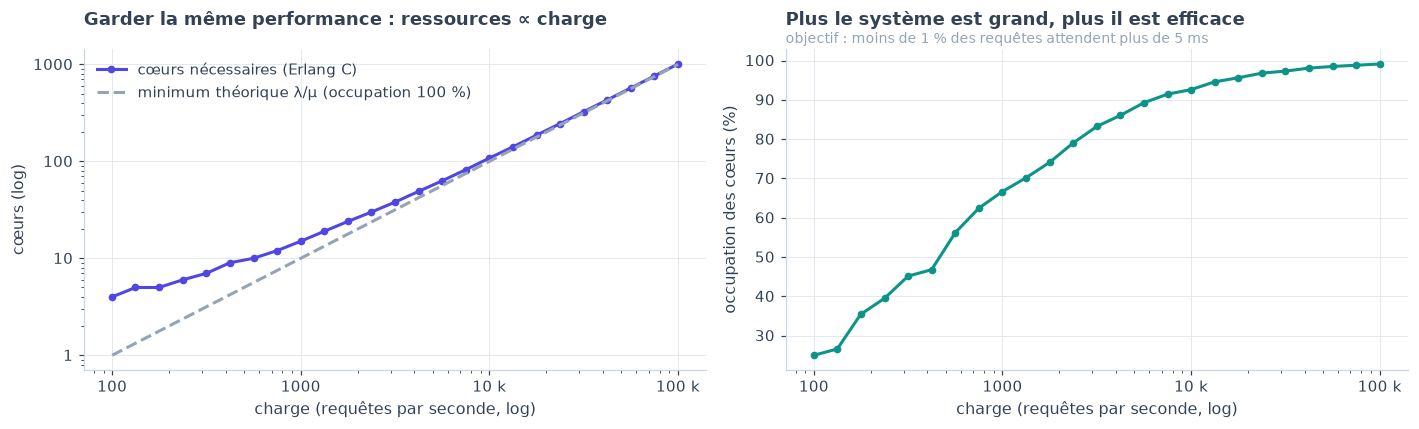

In [2]:
def coeurs_necessaires(lam, mu=100.0, t=0.005, cible=0.01):
    c = max(1, math.ceil(lam / mu))
    while rq.erlang_c(c, lam / mu) * math.exp(-(c * mu - lam) * t) >= cible:
        c += 1
    return c

charges = np.unique(np.logspace(2, 5, 25).astype(int))
cn = np.array([coeurs_necessaires(float(l)) for l in charges])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax.loglog(charges, cn, "o-", color=INDIGO, ms=4, label="cœurs nécessaires (Erlang C)")
ax.loglog(charges, charges / 100, "--", color=GRAY, label="minimum théorique λ/µ (occupation 100 %)")
rq.plain_log_axis(ax)
ax.set_xlabel("charge (requêtes par seconde, log)"); ax.set_ylabel("cœurs (log)")
ax.set_title("Garder la même performance : ressources ∝ charge")
ax.legend(loc="upper left")
ax2.semilogx(charges, charges / 100 / cn * 100, "o-", color=TEAL, ms=4)
rq.plain_log_axis(ax2, "x")
ax2.set_xlabel("charge (requêtes par seconde, log)"); ax2.set_ylabel("occupation des cœurs (%)")
ax2.set_title("Plus le système est grand, plus il est efficace")
subtitle(ax2, "objectif : moins de 1 % des requêtes attendent plus de 5 ms")
plt.tight_layout(); plt.show()

Les ressources nécessaires croissent presque **linéairement** avec la charge : doubler
les cœurs permet de servir deux fois plus de requêtes à performance égale, ce qu'on
appelle une **scalabilité linéaire**. Le graphique de droite montre même un net effet
d'échelle : pour le même objectif, un petit service doit rester occupé à 25 % à peine,
alors qu'un grand peut dépasser 95 %, car les fluctuations s'y compensent mieux (c'est
la mutualisation du cours 3). Dans la réalité, c'est plutôt
l'inverse qui guette : le coût croît souvent **plus vite** que la charge, parce que
traiter une requête devient plus cher quand il y a plus de données, ou parce que les
machines doivent se coordonner (section 3).

> **À retenir.** La scalabilité se discute pour une croissance donnée : à ressources
> fixes, comment la performance se dégrade ; à performance fixe, comment les ressources
> doivent croître. L'idéal est la scalabilité linéaire.

## 2. Monter en gamme ou multiplier les machines (section *Approaches for Coping with Load* et introduction de la partie II)

Trois architectures pour ajouter des ressources :

- **mémoire partagée** (shared-memory) : une machine plus puissante, plus de cœurs, de
  mémoire et de disques ; tous les fils d'exécution voient la même mémoire. C'est la
  **montée en gamme** (scaling up, scalabilité verticale) ;
- **disques partagés** (shared-disk) : plusieurs machines avec leurs propres processeurs
  et mémoire, mais un même ensemble de disques accessible par un réseau rapide (NAS, SAN) ;
  la contention et les verrous limitent son extensibilité ;
- **rien de partagé** (shared-nothing) : des nœuds indépendants, chacun avec ses
  processeurs, sa mémoire et ses disques, qui ne se coordonnent que par messages sur un
  réseau ordinaire. C'est la **multiplication des machines** (scaling out, scalabilité
  horizontale).

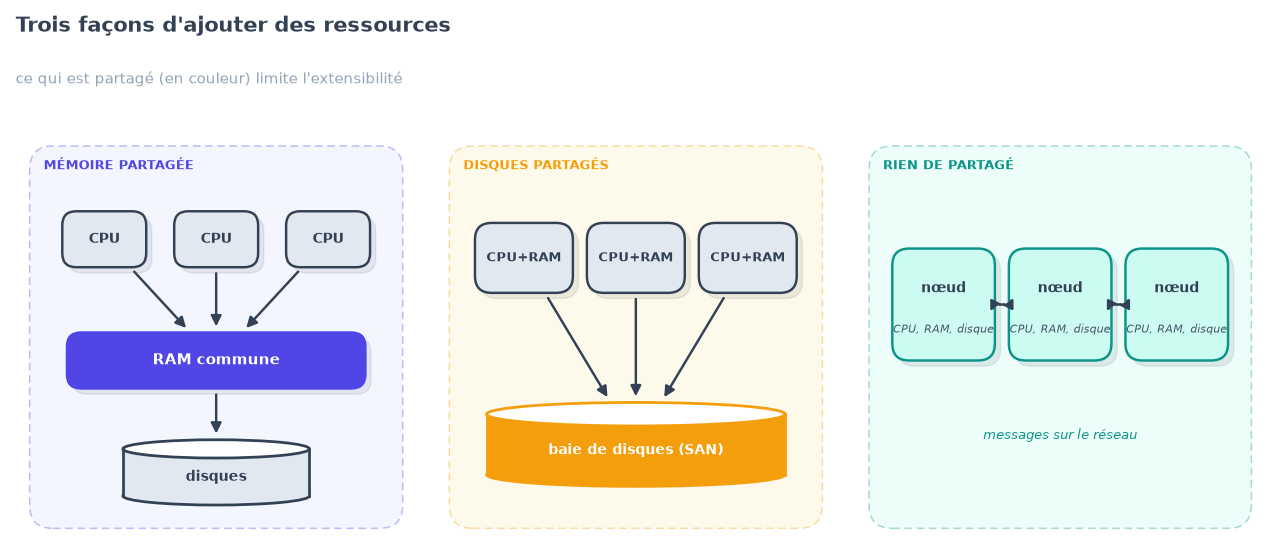

In [3]:
d = Diagram(13.5, 4.8, title="Trois façons d'ajouter des ressources",
            subtitle="ce qui est partagé (en couleur) limite l'extensibilité")
# mémoire partagée
d.group(0.2, 0.2, 4.2, 4.3, "mémoire partagée", color=INDIGO)
d.box("ram", 2.2, 2.0, "RAM commune", color=INDIGO, w=3.2, h=0.6, filled=True, fontsize=9.5)
for i, x in enumerate([1.0, 2.2, 3.4]):
    d.box(f"c{i}", x, 3.3, "CPU", color=SLATE, w=0.9, h=0.6, fontsize=9)
    d.arrow(f"c{i}", "ram")
d.box("disk0", 2.2, 0.8, "disques", color=SLATE, kind="db", w=2.0, h=0.7, fontsize=9)
d.arrow("ram", "disk0")
# disques partagés
d.group(4.7, 0.2, 8.7, 4.3, "disques partagés", color=AMBER)
d.box("san", 6.7, 1.1, "baie de disques (SAN)", color=AMBER, kind="db", w=3.2, h=0.9, filled=True, fontsize=9)
for i, x in enumerate([5.5, 6.7, 7.9]):
    d.box(f"n{i}", x, 3.1, "CPU+RAM", color=SLATE, w=1.05, h=0.75, fontsize=8.5)
    d.arrow(f"n{i}", "san")
# rien de partagé
d.group(9.2, 0.2, 13.3, 4.3, "rien de partagé", color=TEAL)
for i, x in enumerate([10.0, 11.25, 12.5]):
    d.box(f"s{i}", x, 2.6, "nœud", sub="CPU, RAM, disque", color=TEAL, w=1.1, h=1.2, fontsize=9)
d.arrow("s0", "s1", both=True, style="dashed")
d.arrow("s1", "s2", both=True, style="dashed")
d.note(11.25, 1.2, "messages sur le réseau", color=TEAL, fontsize=8.5)
d.show()

**Le problème de la montée en gamme est le coût.** Une machine deux fois plus puissante
coûte nettement plus du double, et ses goulets d'étranglement internes l'empêchent de
traiter deux fois plus de charge. Illustrons avec un **barème fictif** mais réaliste dans
sa forme : le prix horaire d'une machine croît comme $c^{1,3}$ en nombre de cœurs $c$, et
son débit suit une loi d'Amdahl (2 % du travail sérialisé par la contention interne).
Pour le rien-partagé, on aligne des machines de 16 cœurs, avec un petit surcoût de
coordination (le débit est divisé par $1 + 0{,}01\,(k-1)$ pour $k$ machines).

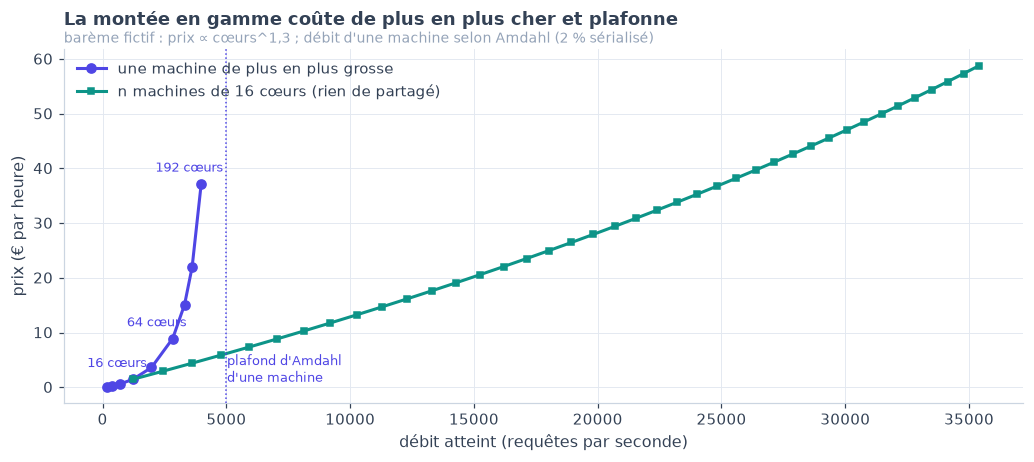

In [4]:
prix = lambda c: 0.04 * c ** 1.3                 # euros par heure, barème fictif
debit_machine = lambda c: 100 * rq.amdahl(c, 0.98)   # req/s, 100 req/s par cœur idéalement
cores_v = np.array([2, 4, 8, 16, 32, 64, 96, 128, 192])
v = pd.DataFrame({"cœurs": cores_v, "débit": debit_machine(cores_v), "prix": prix(cores_v)})
k = np.arange(1, 41)
h = pd.DataFrame({"machines": k, "débit": k * debit_machine(16) / (1 + 0.01 * (k - 1)), "prix": k * prix(16)})
fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.plot(v["débit"], v["prix"], "o-", color=INDIGO, label="une machine de plus en plus grosse")
for _, r in v.iterrows():
    if r["cœurs"] in (16, 64, 192):
        ax.annotate(f"{r['cœurs']:.0f} cœurs", (r["débit"], r["prix"]), (-30, 8), textcoords="offset points",
                    fontsize=8.5, color=INDIGO)
ax.plot(h["débit"], h["prix"], "s-", color=TEAL, ms=3.5, label="n machines de 16 cœurs (rien de partagé)")
ax.axvline(debit_machine(10_000), color=INDIGO, ls=":", lw=1)
ax.text(debit_machine(10_000) * 1.01, 1, "plafond d'Amdahl\nd'une machine", color=INDIGO, fontsize=8.5)
ax.set_xlabel("débit atteint (requêtes par seconde)"); ax.set_ylabel("prix (€ par heure)")
ax.set_title("La montée en gamme coûte de plus en plus cher et plafonne")
subtitle(ax, "barème fictif : prix ∝ cœurs^1,3 ; débit d'une machine selon Amdahl (2 % sérialisé)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

La grosse machine est compétitive tant qu'elle reste moyenne ; au-delà, chaque requête
par seconde supplémentaire coûte de plus en plus cher, et un plafond infranchissable
apparaît (une machine ne dépassera jamais 50 fois le débit d'un cœur avec 2 % de travail
sérialisé). L'architecture sans partage peut, elle, croître presque linéairement, choisir
le matériel au meilleur rapport prix/performance, ajuster ses ressources à la hausse
comme à la baisse, et tolérer la perte d'un centre de données. Le prix à payer : il faut
découper explicitement les données (partitionnement, chapitre
6) et affronter toute la complexité des systèmes distribués (chapitre
8). En pratique, on combine souvent les deux : quelques machines
raisonnablement puissantes.

> **À retenir.** Monter en gamme (mémoire partagée) est simple mais coûte de plus en plus
> cher et plafonne ; les disques partagés butent sur la contention ; le rien-partagé
> passe à l'échelle presque linéairement, au prix du découpage des données et de la
> complexité des systèmes distribués.

## 3. Les limites de la parallélisation : Amdahl et la loi universelle de scalabilité

Pourquoi un système ne passe-t-il pas à l'échelle linéairement ? Deux modèles simples,
qui ne sont pas dans le livre mais éclairent ses propos.

**Loi d'Amdahl.** Si une fraction $1-p$ du travail est sérialisée (un verrou global, un
leader unique), l'accélération sur $n$ processeurs est
$$S(n) = \frac{1}{(1-p) + p/n} \xrightarrow[n \to \infty]{} \frac{1}{1-p}.$$

**Loi universelle de scalabilité** (USL, Neil Gunther). Elle ajoute un terme de
**cohérence** : les nœuds doivent échanger entre eux (invalider des caches, se mettre
d'accord), un coût qui croît comme le nombre de paires, en $n^2$ :
$$X(n) = \frac{\lambda\, n}{1 + \sigma (n-1) + \kappa\, n (n-1)}.$$
$\sigma$ mesure la **contention** (comme Amdahl), $\kappa$ la **cohérence**. Dès que
$\kappa > 0$, le débit passe par un **maximum** en $n^* = \sqrt{(1-\sigma)/\kappa}$
puis **diminue** : ajouter des machines ralentit le système.

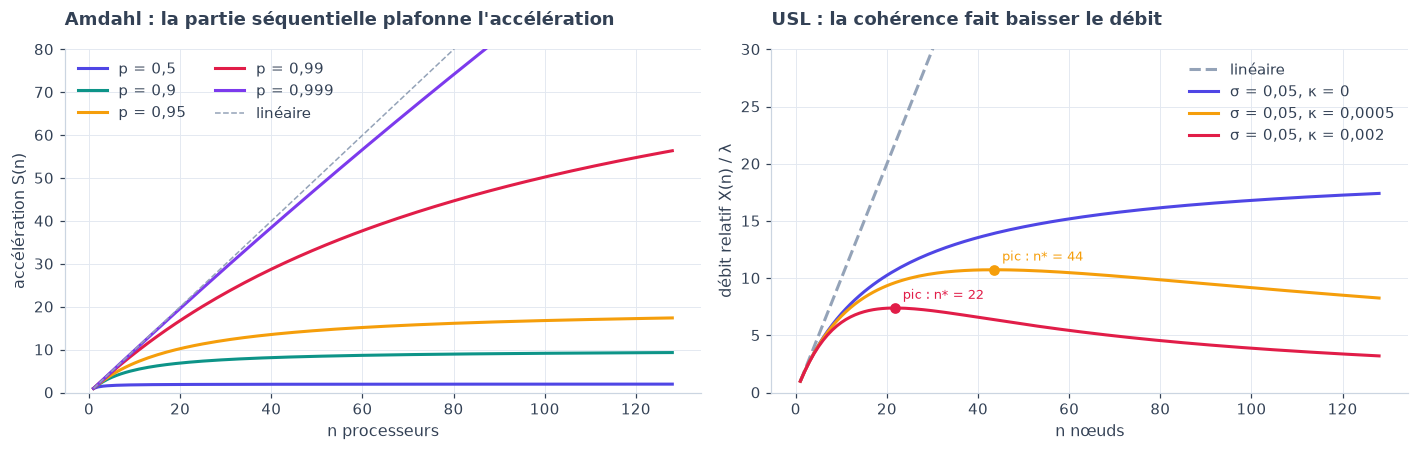

In [5]:
n = np.arange(1, 129)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for p_, c in zip([0.5, 0.9, 0.95, 0.99, 0.999], COLORS):
    ax.plot(n, rq.amdahl(n, p_), color=c, label=f"p = {p_:g}".replace(".", ","))
ax.plot(n, n, "--", color=GRAY, lw=1, label="linéaire")
ax.set_ylim(0, 80); ax.set_xlabel("n processeurs"); ax.set_ylabel("accélération S(n)")
ax.set_title("Amdahl : la partie séquentielle plafonne l'accélération")
ax.legend(loc="upper left", ncol=2)
for (s_, k_), c in zip([(0.0, 0.0), (0.05, 0.0), (0.05, 0.0005), (0.05, 0.002)], [GRAY, INDIGO, AMBER, ROSE]):
    lab = "linéaire" if s_ == 0 else f"σ = {s_:g}, κ = {k_:g}".replace(".", ",")
    ax2.plot(n, rq.usl(n, s_, k_), color=c, ls="--" if s_ == 0 else "-", label=lab)
    if k_ > 0:
        npk = rq.usl_peak(s_, k_)
        ax2.plot(npk, rq.usl(npk, s_, k_), "o", color=c)
        ax2.annotate(f"pic : n* = {npk:.0f}", (npk, rq.usl(npk, s_, k_)), (5, 6), textcoords="offset points",
                     fontsize=8.5, color=c)
ax2.set_ylim(0, 30); ax2.set_xlabel("n nœuds"); ax2.set_ylabel("débit relatif X(n) / λ")
ax2.set_title("USL : la cohérence fait baisser le débit")
ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()

**En pratique**, on mesure le débit pour quelques tailles de cluster et on ajuste l'USL
(`rq.fit_usl`, linéarisation puis moindres carrés) pour prévoir le comportement au-delà.
Voici des mesures synthétiques (bruit de 3 %) d'un système dont les vrais paramètres sont
$\lambda = 1000$, $\sigma = 0{,}05$, $\kappa = 0{,}002$ ; on n'ajuste que sur les mesures
jusqu'à 16 nœuds, comme si l'on cherchait à prévoir la suite.

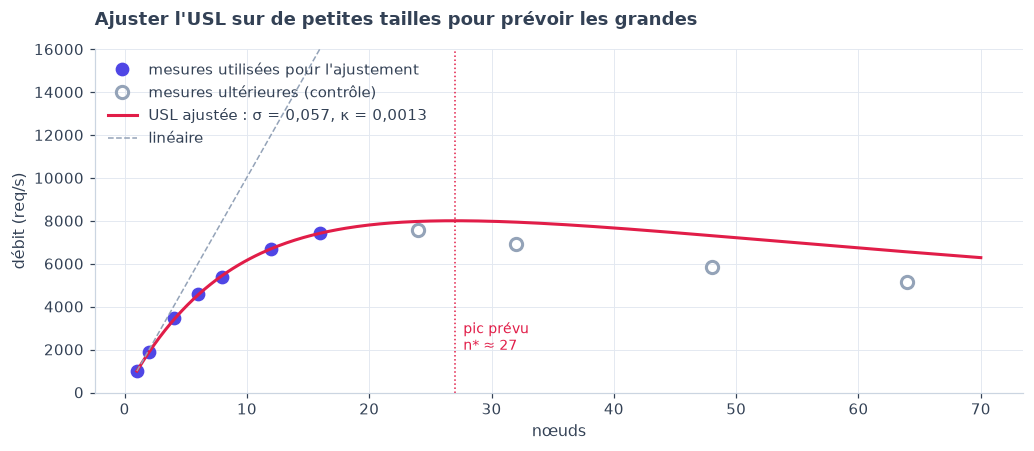

,vrai,ajusté (n ≤ 16)
λ,1000,1004
σ,"0,05","0,05664"
κ,"0,002","0,001295"
n*,"21,79","26,99"


In [6]:
n_mes = np.array([1, 2, 4, 6, 8, 12, 16, 24, 32, 48, 64])
x_mes = rq.usl(n_mes, 0.05, 0.002, 1000) * (1 + rng.normal(0, 0.03, n_mes.size))
train = n_mes <= 16
lam_f, sig_f, kap_f = rq.fit_usl(n_mes[train], x_mes[train])
nn = np.linspace(1, 70, 300)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(n_mes[train], x_mes[train], "o", color=INDIGO, ms=8, label="mesures utilisées pour l'ajustement")
ax.plot(n_mes[~train], x_mes[~train], "o", color=GRAY, ms=8, mfc="none", mew=2, label="mesures ultérieures (contrôle)")
ax.plot(nn, rq.usl(nn, sig_f, kap_f, lam_f), color=ROSE, label=f"USL ajustée : σ = {sig_f:.3f}, κ = {kap_f:.4f}".replace(".", ","))
ax.plot(nn, lam_f * nn, "--", color=GRAY, lw=1, label="linéaire")
npk = rq.usl_peak(sig_f, kap_f)
ax.axvline(npk, color=ROSE, ls=":", lw=1)
ax.text(npk + 0.7, 2000, f"pic prévu\nn* ≈ {npk:.0f}", color=ROSE, fontsize=9)
ax.set_ylim(0, 16000); ax.set_xlabel("nœuds"); ax.set_ylabel("débit (req/s)")
ax.set_title("Ajuster l'USL sur de petites tailles pour prévoir les grandes")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
pd.DataFrame({"vrai": [1000, 0.05, 0.002, rq.usl_peak(0.05, 0.002)], "ajusté (n ≤ 16)": [lam_f, sig_f, kap_f, npk]},
             index=["λ", "σ", "κ", "n*"]).map(lambda v: f"{v:.4g}".replace(".", ","))

L'ajustement sur des clusters de 16 nœuds au plus prévoit que le débit culminera entre
20 et 30 nœuds puis baissera, ce que confirment les mesures de contrôle (le vrai pic est
à 22 nœuds ; avec si peu de mesures bruitées, $\kappa$ est estimé grossièrement). Le modèle est rudimentaire, mais il donne un ordre de grandeur précieux avant
d'acheter du matériel, et il dit **quoi** améliorer : réduire $\sigma$ (moins de
sérialisation) déplace le plafond, réduire $\kappa$ (moins de coordination entre nœuds)
repousse le pic. C'est tout l'objet des chapitres sur le partitionnement et le
traitement de flux : découper en morceaux **indépendants**, qui n'ont pas à se coordonner.

> **À retenir.** La sérialisation (σ) plafonne l'accélération (Amdahl) ; la coordination
> entre nœuds (κ, en $n^2$) la fait même diminuer au-delà d'un pic (USL). Pour passer à
> l'échelle, il faut des composants qui n'ont pas besoin de se parler.

## 4. Pas de recette magique (section *Approaches for Coping with Load*)

L'architecture d'un système à grande échelle est très spécifique à son application : il
n'existe pas de « sauce magique » de la scalabilité. Le livre donne un exemple frappant :
un système conçu pour 100 000 requêtes de 1 ko par seconde ne ressemble en rien à un
système conçu pour 3 requêtes de 2 Go par minute, alors que le débit de données est le
même (100 Mo/s).

In [7]:
cas = pd.DataFrame({
    "requêtes / s": ["100 000", "0,05 (3 par minute)"],
    "taille d'une requête": ["1 ko", "2 Go"],
    "débit de données": ["100 Mo/s", "100 Mo/s"],
    "temps de transfert d'une requête à 1 Go/s": ["1 µs", "2 s"],
    "mémoire tampon par requête en cours": ["1 ko", "jusqu'à 2 Go (sauf traitement en flux)"],
    "goulot probable": ["CPU par requête, connexions, verrous", "réseau, disque, mémoire par requête"],
}, index=["beaucoup de petites requêtes", "peu de grosses requêtes"]).T
cas

,beaucoup de petites requêtes,peu de grosses requêtes
requêtes / s,100 000,"0,05 (3 par minute)"
taille d'une requête,1 ko,2 Go
débit de données,100 Mo/s,100 Mo/s
temps de transfert d'une requête à 1 Go/s,1 µs,2 s
mémoire tampon par requête en cours,1 ko,jusqu'à 2 Go (sauf traitement en flux)
goulot probable,"CPU par requête, connexions, verrous","réseau, disque, mémoire par requête"


Le premier système doit minimiser le coût fixe par requête (analyse, connexions,
verrous) ; le second doit faire circuler de gros volumes sans les copier en mémoire. Les
principes qui restent généraux :

- une architecture adaptée à un niveau de charge l'est rarement à dix fois plus : un
  service en forte croissance doit s'attendre à être **repensé à chaque ordre de
  grandeur**, et il est rarement utile de planifier plus d'un ordre de grandeur à
  l'avance ;
- **découper** le système en composants largement indépendants (c'est l'idée commune au
  partitionnement, aux microservices, au traitement de flux et au rien-partagé) ; la difficulté est de
  savoir où tracer les frontières ;
- ne pas compliquer inutilement : si une base sur une seule machine suffit, elle est
  préférable à un système distribué compliqué.

**Élasticité.** Certains systèmes ajoutent automatiquement des ressources quand la
charge augmente (systèmes *élastiques*), d'autres sont
dimensionnés à la main. L'élasticité est utile si la charge est imprévisible, mais un
système dimensionné manuellement réserve moins de surprises en exploitation. Comparons
sur une journée simulée : dimensionnement fixe pour le pic, contre un automate qui vise
70 % d'occupation, réévalue toutes les 5 minutes et met 10 minutes à démarrer un serveur.

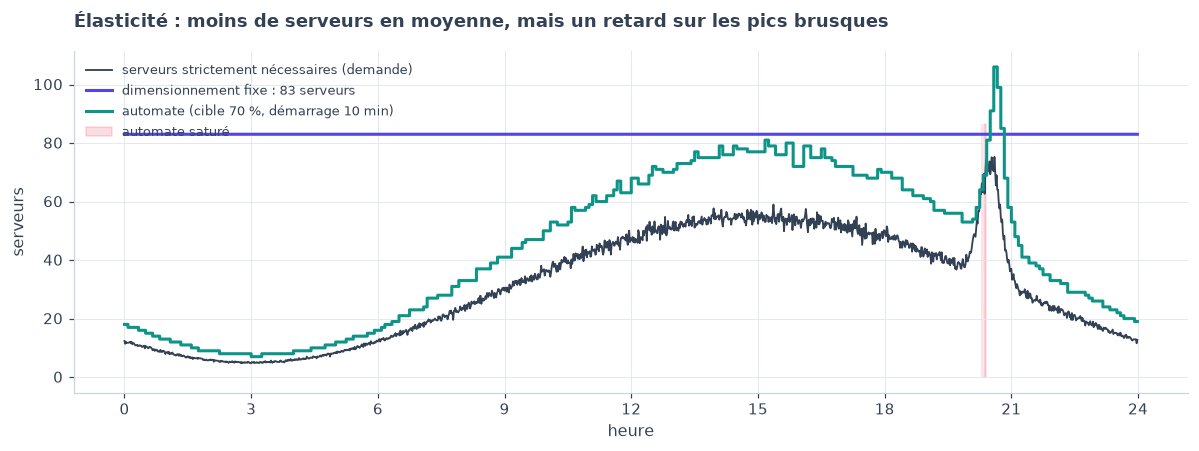

,serveurs-heures,minutes de saturation
fixe (pic + 10 %),1992.0,0
automate,1042.0,4


In [8]:
minutes = np.arange(24 * 60)
demande = 3000 + 2500 * np.sin(2 * np.pi * (minutes / 60 - 9) / 24)
demande += 4000 * np.exp(-0.5 * ((minutes - 20.5 * 60) / 15) ** 2)          # pic du soir
demande *= 1 + rng.normal(0, 0.03, minutes.size)
cap_serveur = 100.0                                                             # req/s par serveur
fixe = math.ceil(demande.max() * 1.1 / cap_serveur)
auto = np.zeros(minutes.size, int)
courant = math.ceil(demande[0] / (0.7 * cap_serveur))
en_attente = []                                                                 # (minute effective, cible)
for m in range(minutes.size):
    if m % 5 == 0 and m > 0:                                                    # décision toutes les 5 min
        voulu = math.ceil(demande[m - 1] / (0.7 * cap_serveur))
        if voulu > courant:
            en_attente.append((m + 10, voulu))                                  # démarrage : 10 min
        else:
            courant, en_attente = voulu, []                                     # arrêt : immédiat
    for t_eff, v_ in [x for x in en_attente if x[0] <= m]:
        courant = max(courant, v_)
    en_attente = [x for x in en_attente if x[0] > m]
    auto[m] = courant
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(minutes / 60, demande / cap_serveur, color=SLATE, lw=1.2, label="serveurs strictement nécessaires (demande)")
ax.plot(minutes / 60, np.full(minutes.size, fixe), color=INDIGO, lw=2, label=f"dimensionnement fixe : {fixe} serveurs")
ax.step(minutes / 60, auto, where="post", color=TEAL, lw=2, label="automate (cible 70 %, démarrage 10 min)")
sature = auto * cap_serveur < demande
ax.fill_between(minutes / 60, 0, demande.max() / cap_serveur * 1.15, where=sature, color=ROSE, alpha=0.15,
                label="automate saturé")
ax.set_xlabel("heure"); ax.set_ylabel("serveurs"); ax.set_xticks(range(0, 25, 3))
ax.set_title("Élasticité : moins de serveurs en moyenne, mais un retard sur les pics brusques")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.show()
pd.DataFrame({"serveurs-heures": [fixe * 24, auto.sum() / 60], "minutes de saturation": [0, int(sature.sum())]},
             index=["fixe (pic + 10 %)", "automate"]).round(0)

L'automate consomme bien moins de serveurs-heures que le dimensionnement fixe, mais il
réagit avec retard : sur la montée brutale du pic du soir, il sature pendant quelques
minutes. Le bon choix dépend de la forme de la charge (prévisible ou non) et du coût
d'une saturation.

> **À retenir.** Il n'existe pas d'architecture scalable universelle : elle dépend des
> paramètres de charge (nombre et taille des requêtes...). On découpe en composants
> indépendants, on repense à chaque ordre de grandeur et on évite la complexité inutile.

## 5. Opérabilité : faciliter la vie de l'exploitation (section *Operability: Making Life Easy for Operations*)

L'essentiel du coût d'un logiciel n'est pas dans son développement initial mais dans sa
**maintenance** : corriger des bogues, le faire tourner, enquêter sur les pannes,
l'adapter à de nouvelles plateformes et de nouveaux usages, rembourser la dette
technique. Le livre retient trois principes : **opérabilité**, **simplicité**,
**évolutivité**.

Une bonne exploitation peut souvent contourner les limites d'un mauvais logiciel, mais un
bon logiciel ne tourne pas de façon fiable avec une mauvaise exploitation. Un système de
données aide l'exploitation en offrant : de la **visibilité** (métriques, supervision,
outils d'observation de son comportement), l'absence de dépendance à une machine
particulière (on peut en arrêter une pour maintenance), une bonne documentation et un
modèle opératoire simple (« si je fais X, il se passe Y »), de bons réglages par défaut
qu'on peut surcharger, de l'auto-réparation avec possibilité de reprendre la main, et un
comportement **prévisible**.

**L'automatisation, une arme à double tranchant.** À grande échelle, la maintenance
manuelle devient hors de prix et l'automatisation indispensable. Mais il reste toujours
des cas limites, rares et complexes, que l'automate ne sait pas traiter : plus on
automatise, plus l'équipe qui gère ces cas doit être compétente. Un modèle jouet de la
charge de travail mensuelle d'une équipe d'exploitation en fonction du nombre de machines :

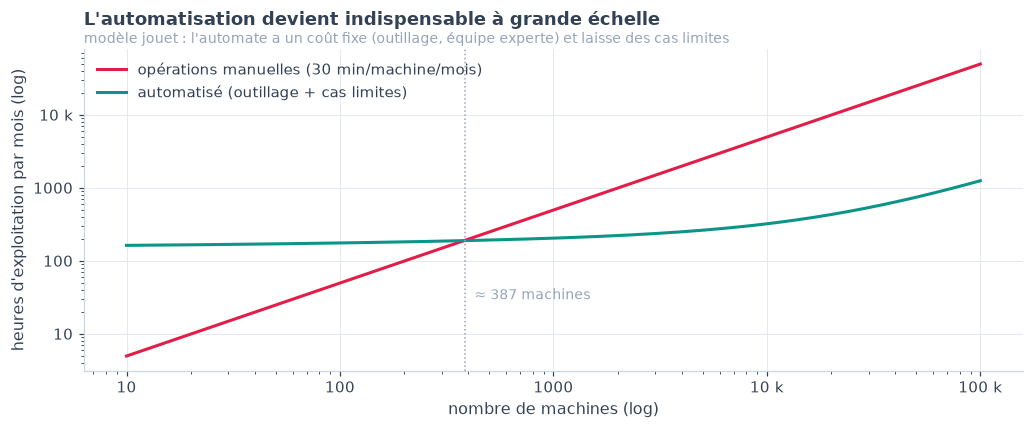

In [9]:
machines = np.logspace(1, 5, 200)
manuel = 0.5 * machines                                     # heures/mois : 30 min par machine
auto_h = 160 + 0.01 * machines + 4 * np.log10(machines) ** 2   # coût fixe + cas limites rares
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.loglog(machines, manuel, color=ROSE, label="opérations manuelles (30 min/machine/mois)")
ax.loglog(machines, auto_h, color=TEAL, label="automatisé (outillage + cas limites)")
x_cross = machines[np.argmax(manuel > auto_h)]
ax.axvline(x_cross, color=GRAY, ls=":", lw=1)
ax.text(x_cross * 1.1, 30, f"≈ {x_cross:.0f} machines", color=GRAY, fontsize=9)
rq.plain_log_axis(ax)
ax.set_xlabel("nombre de machines (log)"); ax.set_ylabel("heures d'exploitation par mois (log)")
ax.set_title("L'automatisation devient indispensable à grande échelle")
subtitle(ax, "modèle jouet : l'automate a un coût fixe (outillage, équipe experte) et laisse des cas limites")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Sous quelques centaines de machines, l'automatisation coûte plus qu'elle ne rapporte ;
au-delà, l'exploitation manuelle devient intenable. Mais l'heure passée par l'équipe
experte sur un cas limite d'un système automatisé est la plus difficile de toutes : un
système automatique qui déraille est souvent plus dur à diagnostiquer qu'un système
piloté à la main. Le bon niveau d'automatisation dépend de l'application et de
l'organisation.

> **À retenir.** L'opérabilité consiste à rendre les tâches courantes faciles :
> visibilité, absence de machine indispensable, comportement prévisible, bons défauts
> surchargeables. L'automatisation est indispensable à grande échelle, mais elle déplace
> la difficulté vers des cas rares qui exigent des experts.

## 6. Simplicité : maîtriser la complexité (section *Simplicity: Managing Complexity*)

Les petits projets ont un code simple et expressif ; en grandissant, beaucoup deviennent
une **grosse boule de boue** (big ball of mud) : tout dépend de tout, chaque changement
risque d'introduire un bogue, les hypothèses cachées et les interactions imprévues se
multiplient. Le livre distingue la complexité **accidentelle**, qui ne vient pas du problème à résoudre mais de la façon de l'implémenter, et qu'il faut chercher à éliminer.

Le meilleur outil contre la complexité est l'**abstraction** : une bonne abstraction
cache beaucoup de détails derrière une façade simple et se réutilise largement. Un
langage de haut niveau cache le code machine et les appels système ; SQL cache les
structures de données sur disque, la concurrence et la reprise après panne. Le livre
s'intéresse aux abstractions générales des systèmes de données : transactions, index,
journaux d'événements.

**Mesurer l'effet d'une abstraction.** Modélisons deux systèmes de 30 modules. Dans la
« boule de boue », chaque module appelle directement 3 modules quelconques. Dans le
système « en couches », les modules sont rangés en 5 couches et chacun n'appelle que 2
modules de la couche juste en dessous, via son interface. Pour chaque module, comptons
combien d'autres modules dépendent de lui, directement ou indirectement : c'est le
**rayon d'impact** d'une modification de ce module.

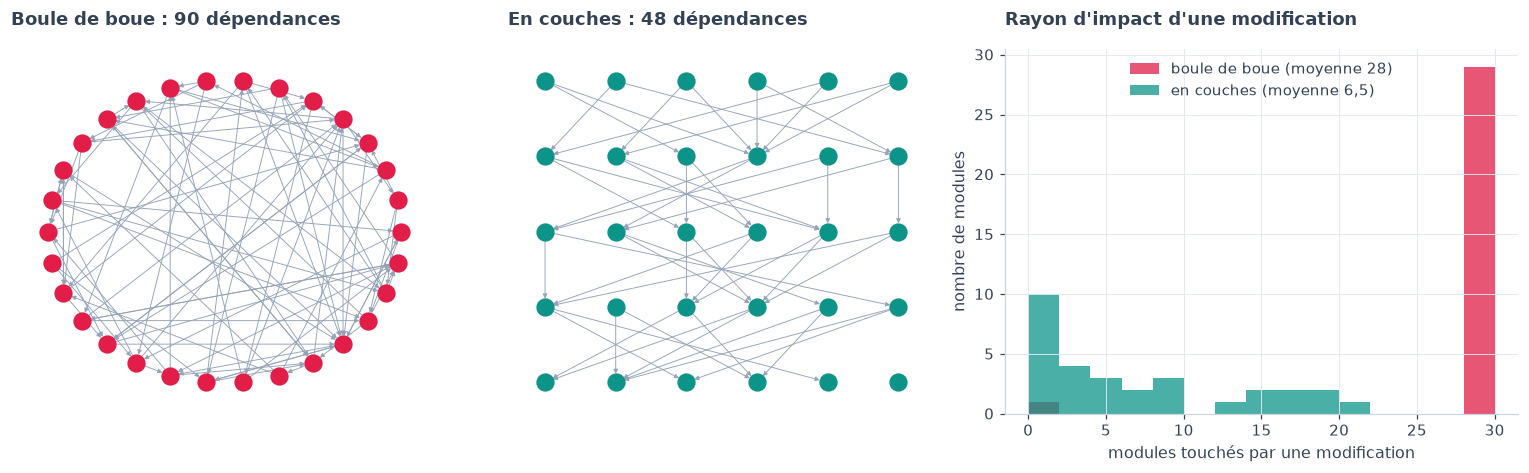

In [10]:
g = np.random.default_rng(4)
n_mod = 30
boue = nx.DiGraph()
boue.add_nodes_from(range(n_mod))
for m in range(n_mod):
    for cible_ in g.choice([x for x in range(n_mod) if x != m], 3, replace=False):
        boue.add_edge(m, int(cible_))                                # m dépend de cible
couches = nx.DiGraph()
couches.add_nodes_from(range(n_mod))
for m in range(n_mod - 6):
    couche = m // 6
    for cible_ in g.choice(range((couche + 1) * 6, (couche + 2) * 6), 2, replace=False):
        couches.add_edge(m, int(cible_))

def rayon(G):
    return np.array([len(nx.ancestors(G, m)) for m in G.nodes])     # modules qui dépendent de m

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 1.2]))
pos_b = nx.circular_layout(boue)
nx.draw_networkx(boue, pos_b, ax=axes[0], node_size=120, node_color=ROSE, edge_color=GRAY, width=0.6,
                 arrowsize=6, with_labels=False)
axes[0].set_title("Boule de boue : 90 dépendances")
pos_c = {m: (m % 6, -(m // 6)) for m in range(n_mod)}
nx.draw_networkx(couches, pos_c, ax=axes[1], node_size=120, node_color=TEAL, edge_color=GRAY, width=0.6,
                 arrowsize=6, with_labels=False)
axes[1].set_title(f"En couches : {couches.number_of_edges()} dépendances")
for a_ in axes[:2]:
    a_.axis("off")
rb, rc = rayon(boue), rayon(couches)
bins = np.arange(0, n_mod + 1, 2)
axes[2].hist(rb, bins=bins, color=ROSE, alpha=0.75, label=f"boule de boue (moyenne {rb.mean():.0f})")
axes[2].hist(rc, bins=bins, color=TEAL, alpha=0.75, label=f"en couches (moyenne {rc.mean():.1f})".replace(".", ","))
axes[2].set_xlabel("modules touchés par une modification"); axes[2].set_ylabel("nombre de modules")
axes[2].set_title("Rayon d'impact d'une modification")
axes[2].legend(loc="upper center")
plt.tight_layout(); plt.show()

Dans la boule de boue, presque tous les modules finissent par dépendre de presque tous
les autres : modifier n'importe lequel peut casser n'importe quoi, et comprendre l'un
exige de comprendre l'ensemble. En couches, avec pourtant un nombre de dépendances
comparable, la plupart des modifications restent locales ; seuls les modules du bas,
derrière des interfaces stables, ont un grand rayon d'impact, et c'est précisément là
qu'on investit en qualité (une base de données bien testée, par exemple). La simplicité
n'est pas « moins de code » : c'est une structure où l'on peut raisonner localement.

> **À retenir.** La complexité ralentit tout le monde et multiplie les bogues. Les bonnes
> abstractions la contiennent : elles cachent les détails derrière une interface et
> limitent la propagation des changements.

## 7. Évolutivité : faciliter le changement (section *Evolvability: Making Change Easy*)

Les exigences changent sans cesse : faits nouveaux, usages imprévus, priorités qui
bougent, plateformes remplacées, réglementation, croissance qui impose de revoir
l'architecture. Côté organisation, les méthodes **agiles** fournissent un cadre pour
s'adapter, avec des outils techniques comme le développement piloté par les tests et le
**refactoring**. Le livre cherche l'agilité au niveau d'un **système de données** fait de
plusieurs applications, et l'appelle **évolutivité** (evolvability) : elle est
étroitement liée à la simplicité et aux abstractions.

Un modèle jouet montre l'enjeu : une équipe livre des fonctionnalités ; chacune ajoute un
peu de couplage, qui rend la suivante plus chère. Une équipe consacre 20 % de son temps
au refactoring, qui réduit le couplage ; l'autre jamais.

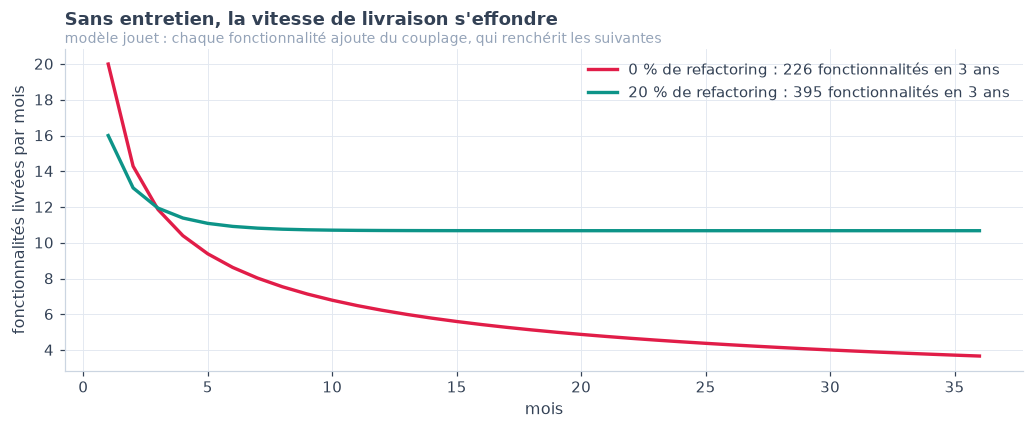

In [11]:
def velocite(refacto, mois=36, capacite=100.0):
    """capacite : jours de travail par mois ; refacto : part consacrée au refactoring."""
    couplage, livrees = 0.0, []
    for _ in range(mois):
        f = capacite * (1 - refacto) / (5.0 * (1 + couplage))   # 5 jours par fonctionnalité sans couplage
        couplage += 0.02 * f                                    # chaque fonctionnalité couple un peu
        couplage *= 1 - 1.5 * refacto                           # le refactoring découple
        livrees.append(f)
    return np.array(livrees)

fig, ax = plt.subplots(figsize=(9.5, 4))
for r_, c in [(0.0, ROSE), (0.2, TEAL)]:
    vel = velocite(r_)
    ax.plot(np.arange(1, 37), vel, color=c, lw=2.2,
            label=f"{r_ * 100:.0f} % de refactoring : {vel.sum():.0f} fonctionnalités en 3 ans")
ax.set_xlabel("mois"); ax.set_ylabel("fonctionnalités livrées par mois")
ax.set_title("Sans entretien, la vitesse de livraison s'effondre")
subtitle(ax, "modèle jouet : chaque fonctionnalité ajoute du couplage, qui renchérit les suivantes")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

L'équipe qui ne refactore jamais livre davantage les premiers mois, puis sa vitesse
s'effondre sous le poids du couplage accumulé ; l'autre maintient un rythme stable et
livre plus au total. Les chiffres sont arbitraires, mais la forme des courbes est celle
qu'observent de nombreuses équipes. Au niveau d'un système de données, les leviers
d'évolutivité que le livre détaillera sont les formats d'encodage compatibles (chapitre
4), les données dérivées que l'on peut recalculer et le traitement de flux
(chapitres 10 et 11).

> **À retenir.** L'évolutivité est l'agilité au niveau d'un système de données. Elle
> découle de la simplicité et des bonnes abstractions : un système faiblement couplé se
> modifie facilement, un système fortement couplé de plus en plus difficilement.